# Thực nghiệm và demo phân loại Spam/Ham bình luận PTIT

**Nhóm Bảo, Cương, Phi, Phương — notebook 02.**

Luồng: **v7 đã chốt → tiền xử lý mô hình → chia tập → BoW/TF-IDF/FastText → NB/SVM
→ đánh giá → dự đoán bình luận mới**. Các module được import từ project; không cần
chạy lại crawler, Argilla hoặc gộp dữ liệu. Notebook 01 trình bày thu thập/gán nhãn.

Mở trong repo, chọn kernel Python 3.12 và **Restart Kernel → Run All**. Có thể dùng
`data/final/labeled_v7.csv` hoặc tải bản HF đã chốt. Ý 4 bổ sung có mục chờ riêng.


## 0. Môi trường và cấu hình

Cell cài đặt chỉ cài khi phiên bản còn thiếu/khác. Trên máy đã cài đúng requirements,
cell sẽ bỏ qua cài đặt. Không đặt API token vào notebook. Môi trường đã kiểm tra là
Python 3.12; phải chọn đúng kernel trước khi chạy.

In [1]:
import os
import importlib.metadata as metadata

PACKAGES = {
    "numpy": "1.26.4", "scipy": "1.13.1", "pandas": "2.2.3",
    "scikit-learn": "1.6.1", "matplotlib": "3.10.3", "joblib": "1.5.1",
    "gensim": "4.4.0", "underthesea": "8.3.0", "huggingface_hub": "0.36.2",
    "jinja2": "3.1.6",
}
missing = []
for name, version in PACKAGES.items():
    try:
        installed = metadata.version(name)
    except metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        missing.append(f"{name}=={version}")
if missing:
    if os.environ.get("SPAMHAM_SKIP_INSTALL") == "1":
        raise RuntimeError("Môi trường chưa khớp: " + ", ".join(missing))
    get_ipython().run_line_magic("pip", "install -q " + " ".join(missing))
else:
    print("Đã có đúng phiên bản thư viện; không cài lại.")


Đã có đúng phiên bản thư viện; không cài lại.


In [2]:
import os, sys
from pathlib import Path

# Mở notebook trong repo; không cần nhúng lại module bằng %%writefile.
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / "pipeline/__init__.py").is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Mở notebook trong thư mục project có pipeline/ và external/.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import re, json, time, hashlib, tempfile
import inspect
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from huggingface_hub import hf_hub_download
from joblib import Memory
import joblib
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             average_precision_score, confusion_matrix, precision_recall_curve)

SEED = 42
np.random.seed(SEED)
N_JOBS = int(os.environ.get("SPAMHAM_N_JOBS", "2"))
ARTIFACT_DIR = Path(os.environ.get("SPAMHAM_OUTPUT_DIR", "artifacts/spamham"))
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
CSV_PATH = os.environ.get("SPAMHAM_CSV", str(PROJECT_ROOT / "data/final/labeled_v7.csv") if (PROJECT_ROOT / "data/final/labeled_v7.csv").is_file() else "")
HF_REPO_ID, DATA_FILENAME = "p-storm/ptit-facebook-comments-spamham", "labeled_v7.csv"
HF_REVISION = "5b904713bb2896ab8f6ff336545b9debd2489724"
EXPECTED_SHA256 = os.environ.get("SPAMHAM_EXPECTED_SHA256", "7305d712996da3ff0dce1ea4142844b7629e9880bcac47ee38934f0b6e6cfbee")
pd.set_option("display.max_colwidth", 100)
ENVIRONMENT = {name: metadata.version(name) for name in PACKAGES}
print("Python:", sys.version.split()[0], "| jobs:", N_JOBS)
display(pd.Series(ENVIRONMENT, name="version").to_frame())


C:\KH086\PT&KP DLVB\PROJECT\ptit-facebook-spam-ham\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.12.14 | jobs: 2


,version
numpy,1.26.4
scipy,1.13.1
pandas,2.2.3
scikit-learn,1.6.1
matplotlib,3.10.3
joblib,1.5.1
gensim,4.4.0
underthesea,8.3.0
huggingface_hub,0.36.2
jinja2,3.1.6


In [3]:
from pipeline.features.spam_features import FastTextVectorizer
from pipeline.prepare import preprocess_for_model as preprocessing_module
from pipeline.features import spam_features as features_module
from pipeline.prepare.preprocess_for_model import preprocess, clean_text, mask_names, STOP_WORDS, EMOJI
from pipeline.modeling.training_utils import (norm_key, bucket, grouped_folds, undersampled_search,
                                              tune_nb_threshold, predict_record)
from pipeline.modeling.experiments import FEATURES, MODELS, make_pipe, fit_experiment, evaluate, boot_ci
from pipeline.inference.predict import predict_spam


## 1. Dataset thực nghiệm v7 — nạp và kiểm tra

V7 do nhóm cung cấp qua HF; khóa revision và hash để dùng cùng một bản cho mọi
thí nghiệm. Đây là bản đầu vào đã có nhãn, không phải file notebook này vừa cào.
Lịch sử nguồn/phiên bản được lưu ở `docs/provenance/`; luồng thu thập minh họa ở
notebook 01. Cell dưới không cần dữ liệu tham chiếu của các đợt trước.


In [4]:
if not CSV_PATH:
    token = os.environ.get("HF_TOKEN")
    if not token and Path("/kaggle").exists():
        try:
            from kaggle_secrets import UserSecretsClient
            token = UserSecretsClient().get_secret("HF_TOKEN")
        except Exception:
            token = None  # dataset công khai không cần token; không in nội dung secret
    try:
        CSV_PATH = hf_hub_download(repo_id=HF_REPO_ID, filename=DATA_FILENAME,
                                   repo_type="dataset", revision=HF_REVISION, token=token)
    except Exception as exc:
        raise RuntimeError("Không tải được CSV. Cung cấp SPAMHAM_CSV hoặc kiểm tra mạng/quyền HF.") from exc
csv_path = Path(CSV_PATH).expanduser()
if not csv_path.is_file():
    raise FileNotFoundError("Không thấy CSV tại đường dẫn cấu hình: " + str(csv_path))
dataset_sha256 = hashlib.sha256(csv_path.read_bytes()).hexdigest()
if EXPECTED_SHA256 and dataset_sha256 != EXPECTED_SHA256:
    raise ValueError("SHA-256 khác bản v7 đã chốt; kiểm tra đúng dữ liệu trước khi huấn luyện.")
raw = pd.read_csv(csv_path, keep_default_na=False, dtype={"id": str})
required = {"id", "label", "cleaned_text"}
if not required.issubset(raw):
    raise ValueError("Thiếu cột bắt buộc: " + str(sorted(required - set(raw))))
raw["label"] = raw["label"].astype(str).str.strip().str.lower()
if not raw["label"].isin(["spam", "ham"]).all():
    raise ValueError("Có nhãn không hợp lệ; đối soát CSV, không tự đổi hoặc bỏ nhãn.")
raw["id"] = raw["id"].astype(str).str.strip()
if raw["id"].eq("").any() or raw["id"].duplicated().any():
    raise ValueError("ID rỗng hoặc trùng; cần đối soát nguồn trước khi chạy.")
raw["cleaned_text"] = raw["cleaned_text"].astype(str)
if raw["cleaned_text"].str.strip().eq("").any():
    raise ValueError("cleaned_text rỗng; cần đối soát, không bỏ dòng âm thầm.")
if "text" not in raw:
    raw["text"] = raw["cleaned_text"]
else:
    raw["text"] = raw["text"].where(raw["text"].astype(str).str.strip().ne(""), raw["cleaned_text"])
if "comment_type" not in raw:
    raw["comment_type"] = "unknown"
y_all = (raw["label"] == "spam").astype(int).to_numpy()
if len(np.unique(y_all)) != 2:
    raise ValueError("Dataset phải có đủ ham và spam.")
exact_keys = raw["cleaned_text"].str.normalize("NFC").str.lower().str.strip()
DATA_AUDIT = {
    "rows": len(raw), "labels": raw["label"].value_counts().to_dict(),
    "duplicate_ids": int(raw["id"].duplicated().sum()),
    "empty_cleaned_text": int(raw["cleaned_text"].str.strip().eq("").sum()),
    "rows_in_repeated_text_groups": int(exact_keys.duplicated(keep=False).sum()),
    "text_groups_with_conflicting_labels": int((raw.groupby(exact_keys)["label"].nunique() > 1).sum()),
}
print("SHA-256:", dataset_sha256)
display(pd.Series(DATA_AUDIT, name="kiểm tra").to_frame())
print("Không đổi nhãn hoặc xóa các nhóm xung đột: cần ngữ cảnh/người gán nhãn xác nhận.")


SHA-256: 7305d712996da3ff0dce1ea4142844b7629e9880bcac47ee38934f0b6e6cfbee


,kiểm tra
rows,38233
labels,"{'ham': 32907, 'spam': 5326}"
duplicate_ids,0
empty_cleaned_text,0
rows_in_repeated_text_groups,2729
text_groups_with_conflicting_labels,27


Không đổi nhãn hoặc xóa các nhóm xung đột: cần ngữ cảnh/người gán nhãn xác nhận.


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,32907.0,11.3,13.3,1.0,5.0,8.0,13.0,667.0
spam,5326.0,13.6,24.3,1.0,2.0,6.0,12.0,315.0


label,ham,spam
comment_type,,
comment,0.842,0.158
reply,0.890,0.110


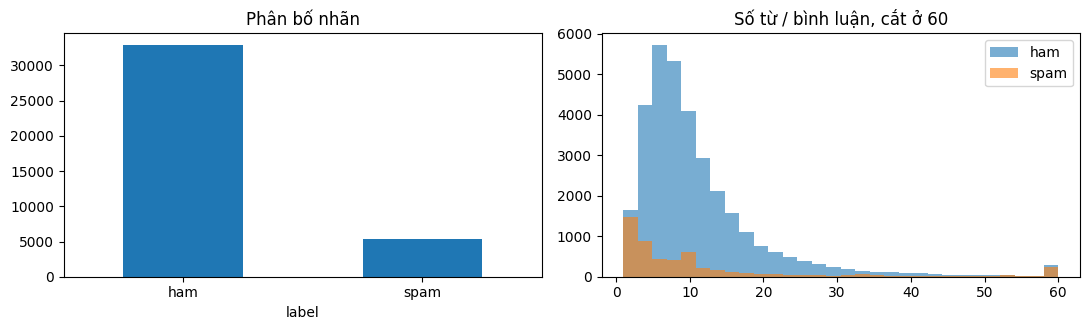

In [5]:
raw["n_words"] = raw["cleaned_text"].str.split().str.len()
display(raw.groupby("label")["n_words"].describe().round(1))
display(pd.crosstab(raw["comment_type"], raw["label"], normalize="index").round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
raw["label"].value_counts().plot.bar(ax=ax[0], rot=0, title="Phân bố nhãn")
for label in ["ham", "spam"]:
    ax[1].hist(raw.loc[raw.label == label, "n_words"].clip(upper=60), bins=30, alpha=.6, label=label)
ax[1].set_title("Số từ / bình luận, cắt ở 60"); ax[1].legend()
plt.tight_layout(); plt.show()


## 2. Tiền xử lý tiếng Việt

Nhánh cổ điển dùng cùng `preprocess` khi train và dự đoán: NFC/HTML, URL → `urltoken`,
SĐT → `phonetoken`, che username và cụm tên đầu câu có điều kiện từ điển, chữ thường,
rút gọn chữ lặp, tách từ underthesea. Emoji gốc được bỏ và nếu có sẽ thêm đúng một
`emoji_token`. Giữ dấu câu để không tự loại tín hiệu của bình luận ngắn.

Che tên chỉ là heuristic bảo thủ, không hứa ẩn danh hoàn toàn. Danh sách họ/tên cố định
kế thừa phần danh sách trong notebook nhóm; nguồn hoten.org là nguồn được bản cũ ghi,
chưa xác minh lại quá trình chọn danh sách. Không tải thêm từ điển GitHub khi chạy.
Không coi mọi cụm viết hoa là tên người. Thử cả giữ/bỏ stop words; không bỏ từ phủ định.

In [6]:
examples = ["Máy Tính học tốt", "Nguyễn Văn An ơi, ib mình nhé", "Người tham gia ẩn danh 123 😂😂",
            "Xem https://example.com hoặc gọi 0901234567 nhé", "không mua nhé"]
display(pd.DataFrame({"đầu vào": examples, "sau xử lý": [preprocess(x, x) for x in examples]}))
assert mask_names("Máy Tính học tốt") == "Máy Tính học tốt"
assert mask_names("Nguyễn Văn An ơi").startswith("user_name")
emoji_example = preprocess("Chào 😂😂", "Chào 😂😂")
assert emoji_example.split().count("emoji_token") == 1 and not EMOJI.search(emoji_example)
assert "urltoken" in preprocess("https://example.com", "https://example.com")
assert "phonetoken" in preprocess("0901234567", "0901234567")
t0 = time.time()
tok_nostop = pd.Series([preprocess(c, t, False) for c, t in zip(raw.cleaned_text, raw.text)])
tok_stop = pd.Series([" ".join(t for t in text.split() if t not in STOP_WORDS) for text in tok_nostop])
TEXT = {"giữ stop words": tok_nostop, "có loại stop words": tok_stop}
print(f"Tiền xử lý {len(raw)} mẫu: {time.time()-t0:.1f}s; không học từ vựng từ test.")


,đầu vào,sau xử lý
0,Máy Tính học tốt,máy_tính học tốt
1,"Nguyễn Văn An ơi, ib mình nhé","user_name ơi , ib mình nhé"
2,Người tham gia ẩn danh 123 😂😂,người tham_gia ẩn_danh 123 emoji_token
3,Xem https://example.com hoặc gọi 0901234567 nhé,xem urltoken hoặc gọi phonetoken nhé
4,không mua nhé,không mua nhé


Tiền xử lý 38233 mẫu: 21.0s; không học từ vựng từ test.


## 3. Chia train/test và cross-validation

Khoảng 80/20 theo hash của khóa văn bản (không dùng nhãn), rồi 5 fold trong train
cũng theo nhóm. Tỷ lệ nhãn không bị ép giống nhau. Câu chỉ dấu câu có khóa theo nội
dung, không gán khóa riêng theo số dòng. Có kiểm tra nhóm không giao nhau và đủ hai lớp.
Chỉ bảo vệ các nhóm theo tiêu chí khóa này; không khẳng định loại hết gần trùng/ngữ cảnh chung.

Mọi lựa chọn siêu tham số, stop words và mô hình dùng CV trong train. Các bảng test
là đánh giá các cấu hình đã chốt. Test từng xuất hiện trong phát triển trước đây, vì vậy
chưa xem đây là một tập holdout mới hoàn toàn độc lập với lịch sử phát triển của nhóm.

In [7]:
keys = raw["cleaned_text"].map(norm_key).to_numpy()
is_test = np.array([bucket(key, "test") == 0 for key in keys])
train_idx, test_idx = np.where(~is_test)[0], np.where(is_test)[0]
y_train, y_test = y_all[train_idx], y_all[test_idx]
assert len(np.unique(y_train)) == len(np.unique(y_test)) == 2
assert not set(keys[train_idx]) & set(keys[test_idx])
CV_FOLDS = grouped_folds(keys[train_idx], y_train)
fold_table = pd.DataFrame([{"fold": i + 1, "train": len(tr), "validation": len(va),
                            "spam_validation": int(y_train[va].sum())} for i, (tr, va) in enumerate(CV_FOLDS)])
display(fold_table)
print(f"Train {len(train_idx)} ({y_train.mean():.1%} spam); test {len(test_idx)} ({y_test.mean():.1%} spam)")
print(f"Baseline toàn ham: Accuracy={1-y_test.mean():.4f}, Recall/F1 spam=0")


,fold,train,validation,spam_validation
0,1,24815,5944,764
1,2,24327,6432,1187
2,3,24554,6205,856
3,4,24529,6230,789
4,5,24811,5948,779


Train 30759 (14.2% spam); test 7474 (12.7% spam)
Baseline toàn ham: Accuracy=0.8728, Recall/F1 spam=0


## 4. Đặc trưng và huấn luyện mô hình cổ điển

3 đặc trưng × 2 họ thuật toán × 2 kiểu stop words = **12 tổ hợp chính**.
BoW/TF-IDF + MultinomialNB hoặc LinearSVC; FastText + GaussianNB hoặc StandardScaler +
LinearSVC. NB cho embedding dùng GaussianNB vì vector có thể âm. FastText/IDF chỉ học
trong train từng fold, pooling mean/TF-IDF; không học embedding trước trên toàn dataset.

SVM tìm cả `class_weight=None` và `balanced` trên CV thay vì mặc định balanced luôn tốt.
FastText dùng một worker và seed cố định; khởi động Python với `PYTHONHASHSEED=42` khi
cần tái lập chặt hơn. Các phiên bản/hệ điều hành khác vẫn có thể tạo sai khác số học.
Cache thuộc một thư mục tạm riêng, tự dọn sau khi chạy; không lẫn kết quả các lần chạy.

Solver dùng `dual=False` sau khi cấu hình auto/dual có cảnh báo hội tụ ở lượt kiểm tra đầu; chọn cấu hình solver không dựa vào điểm test.

In [8]:
# Grid/cấu hình nằm ở pipeline/modeling/experiments.py: make_pipe().
# Fit vectorizer và model trong train của từng fold, không fit trên test.
cache_dir = tempfile.TemporaryDirectory(prefix="spamham_cache_", dir=ARTIFACT_DIR)
cache = Memory(cache_dir.name, verbose=0)
RESULTS = []
for pre in TEXT:
    X_train_text = TEXT[pre].iloc[train_idx].to_numpy()
    for feature in FEATURES:
        for algorithm in MODELS:
            result = fit_experiment(pre, feature, algorithm, X_train_text, y_train, CV_FOLDS,
                                    seed=SEED, cache=cache, n_jobs=N_JOBS)
            RESULTS.append(result)
            print(pre, feature, algorithm, f"CV F1={result['CV F1 (spam)']:.4f}", result["Tham số"], flush=True)


giữ stop words BoW Naive Bayes CV F1=0.6077 {'clf__alpha': 1.0, 'vec__ngram_range': (1, 2)}


giữ stop words BoW SVM CV F1=0.7091 {'clf__C': 1.0, 'clf__class_weight': None, 'vec__ngram_range': (1, 2)}


giữ stop words TF-IDF Naive Bayes CV F1=0.5959 {'clf__alpha': 0.1, 'vec__ngram_range': (1, 2)}


giữ stop words TF-IDF SVM CV F1=0.7736 {'clf__C': 0.3, 'clf__class_weight': None, 'vec__ngram_range': (1, 2)}


giữ stop words FastText Naive Bayes CV F1=0.5594 {'clf__var_smoothing': 0.001, 'vec__pooling': 'tfidf'}


giữ stop words FastText SVM CV F1=0.6794 {'clf__C': 1.0, 'clf__class_weight': None, 'vec__pooling': 'mean'}


... (2 outputs left out)

có loại stop words TF-IDF Naive Bayes CV F1=0.5835 {'clf__alpha': 0.1, 'vec__ngram_range': (1, 2)}


có loại stop words TF-IDF SVM CV F1=0.7562 {'clf__C': 1.0, 'clf__class_weight': None, 'vec__ngram_range': (1, 2)}


có loại stop words FastText Naive Bayes CV F1=0.4894 {'clf__var_smoothing': 0.001, 'vec__pooling': 'mean'}


có loại stop words FastText SVM CV F1=0.6653 {'clf__C': 1.0, 'clf__class_weight': None, 'vec__pooling': 'mean'}


### Chọn tiền xử lý và các thí nghiệm bổ sung bằng train/CV

Chọn tổ hợp chính tốt nhất trên cả 12 tổ hợp theo F1-CV; dùng kiểu stop words của tổ
hợp đó làm bảng sáu mô hình chính. Bảng trung bình CV dưới đây chỉ là mô tả, không
dùng test để quyết định. Các thí nghiệm mất cân bằng là phần nâng cao, đề không yêu
cầu riêng; giữ lại vì đã có trong bài và sửa cho cùng quy tắc CV.

In [9]:
best_main = max(RESULTS, key=lambda r: r["CV F1 (spam)"])
MAIN_PRE = best_main["Tiền xử lý"]
display(pd.DataFrame(RESULTS).groupby("Tiền xử lý")["CV F1 (spam)"].mean().to_frame())
print("Tiền xử lý của tổ hợp chính được chọn:", MAIN_PRE)


,CV F1 (spam)
Tiền xử lý,
có loại stop words,0.621925
giữ stop words,0.654198


Tiền xử lý của tổ hợp chính được chọn: giữ stop words


In [10]:
X_tr_text = TEXT[MAIN_PRE].iloc[train_idx].to_numpy()
SUPPLEMENTARY = []
# Hai nhánh cố định class weight: cùng grid C/ngram và cùng CV_FOLDS.
for weight in [None, "balanced"]:
    pipe, grid, jobs = make_pipe("TF-IDF", "SVM", seed=SEED, cache=cache, n_jobs=N_JOBS)
    grid["clf__class_weight"] = [weight]
    start = time.time()
    search = GridSearchCV(pipe, grid, scoring="f1", cv=CV_FOLDS,
                          n_jobs=N_JOBS, refit=True, error_score="raise").fit(X_tr_text, y_train)
    SUPPLEMENTARY.append({"Tiền xử lý": MAIN_PRE, "Đặc trưng": "TF-IDF", "Thuật toán": "SVM",
        "Biến thể": f"class_weight={weight}", "CV F1 (spam)": search.best_score_,
        "Tham số": search.best_params_, "Thời gian (s)": time.time()-start, "_model": search.best_estimator_})

# OOF chỉ trong train; clone để không thay đổi model của thí nghiệm chính.
nb_record = next(r for r in RESULTS if r["Tiền xử lý"] == MAIN_PRE and r["Đặc trưng"] == "TF-IDF" and r["Thuật toán"] == "Naive Bayes")
start = time.time()
nb_model, nb_cv, threshold = tune_nb_threshold(nb_record["_model"], X_tr_text, y_train, CV_FOLDS)
SUPPLEMENTARY.append({"Tiền xử lý": MAIN_PRE, "Đặc trưng": "TF-IDF", "Thuật toán": "Naive Bayes",
    "Biến thể": "chỉnh ngưỡng", "CV F1 (spam)": nb_cv,
    "Tham số": {**nb_record["Tham số"], "threshold": threshold}, "Thời gian (s)": time.time()-start,
    "_model": nb_model, "_threshold": threshold})

# Under-sampling chỉ trong train của mỗi fold; validation không bị lấy mẫu.
pipe, grid, _ = make_pipe("TF-IDF", "SVM", seed=SEED, cache=cache, n_jobs=N_JOBS)
grid["clf__class_weight"] = [None]
start = time.time()
us_model, us_cv, us_params, us_count = undersampled_search(pipe, grid, X_tr_text, y_train, CV_FOLDS, SEED)
SUPPLEMENTARY.append({"Tiền xử lý": MAIN_PRE, "Đặc trưng": "TF-IDF", "Thuật toán": "SVM",
    "Biến thể": "under-sampling 2:1", "CV F1 (spam)": us_cv, "Tham số": us_params,
    "Thời gian (s)": time.time()-start, "_model": us_model})
CANDIDATES = RESULTS + SUPPLEMENTARY
best = max(CANDIDATES, key=lambda r: r["CV F1 (spam)"])
print("Chọn theo CV trước đánh giá test:", {k: v for k, v in best.items() if not k.startswith("_")})
print("Under-sampling full train còn", us_count, "mẫu; ngưỡng NB", round(threshold, 4))


Chọn theo CV trước đánh giá test: {'Tiền xử lý': 'giữ stop words', 'Đặc trưng': 'TF-IDF', 'Thuật toán': 'SVM', 'Biến thể': 'chính', 'CV F1 (spam)': 0.7735613299500151, 'Tham số': {'clf__C': 0.3, 'clf__class_weight': None, 'vec__ngram_range': (1, 2)}, 'Thời gian (s)': 17.30835199356079}
Under-sampling full train còn 13125 mẫu; ngưỡng NB 0.1721


### 4 bổ sung. Mô hình hiện đại — CHƯA THỰC HIỆN

Theo yêu cầu hiện tại, dành vị trí cho phần này và làm ở lượt sau. Chưa có huấn luyện,
kết quả hoặc kết luận về mô hình hiện đại; chưa thể tuyên bố đủ toàn bộ đề bài.

In [11]:
# Dành cho phần mô hình hiện đại ở lượt sau.


## 5. Đánh giá trên test

Nhãn dương là **spam = 1**, ham = 0. Các chỉ số bắt buộc: Accuracy, Precision, Recall,
F1 và Confusion Matrix. **AP (Average Precision)** và PR curve là phần thêm, không gọi
AP là diện tích hình thang PR. Mô hình cuối được chọn theo CV ở cell trước, không theo test.

In [12]:
for record in CANDIDATES:
    evaluate(record, TEXT[record["Tiền xử lý"]].iloc[test_idx].to_numpy(), y_test)
METRICS = ["Accuracy", "Precision", "Recall", "F1", "AP"]
REPORT_COLS = ["Tiền xử lý", "Đặc trưng", "Thuật toán", "Biến thể", "CV F1 (spam)", *METRICS, "Tham số", "Thời gian (s)"]
metrics = pd.DataFrame([{k: r[k] for k in REPORT_COLS} for r in CANDIDATES])
sel = [r for r in RESULTS if r["Tiền xử lý"] == MAIN_PRE]
display(metrics[(metrics["Tiền xử lý"] == MAIN_PRE) & (metrics["Biến thể"] == "chính")].round(4))
display(metrics[metrics["Biến thể"] != "chính"].round(4))
print("Mô hình cuối theo CV:", best["Đặc trưng"], best["Thuật toán"], best["Biến thể"], best["Tiền xử lý"])
print(f"Test F1={best['F1']:.4f}, Precision={best['Precision']:.4f}, Recall={best['Recall']:.4f}")


,Tiền xử lý,Đặc trưng,Thuật toán,Biến thể,CV F1 (spam),Accuracy,Precision,Recall,F1,AP,Tham số,Thời gian (s)
0,giữ stop words,BoW,Naive Bayes,chính,0.6077,0.9141,0.7441,0.4953,0.5947,0.7320,"{'clf__alpha': 1.0, 'vec__ngram_range': (1, 2)}",8.1979
1,giữ stop words,BoW,SVM,chính,0.7091,0.9241,0.7110,0.6803,0.6953,0.7492,"{'clf__C': 1.0, 'clf__class_weight': None, 'vec__ngram_range': (1, 2)}",458.3321
2,giữ stop words,TF-IDF,Naive Bayes,chính,0.5959,0.9257,0.8402,0.5142,0.6380,0.7988,"{'clf__alpha': 0.1, 'vec__ngram_range': (1, 2)}",6.2843
3,giữ stop words,TF-IDF,SVM,chính,0.7736,0.9419,0.8818,0.6278,0.7334,0.8117,"{'clf__C': 0.3, 'clf__class_weight': None, 'vec__ngram_range': (1, 2)}",17.3084
4,giữ stop words,FastText,Naive Bayes,chính,0.5594,0.8493,0.4374,0.6425,0.5204,0.5360,"{'clf__var_smoothing': 0.001, 'vec__pooling': 'tfidf'}",155.6572
5,giữ stop words,FastText,SVM,chính,0.6794,0.9253,0.8259,0.5237,0.6409,0.7179,"{'clf__C': 1.0, 'clf__class_weight': None, 'vec__pooling': 'mean'}",105.1103


,Tiền xử lý,Đặc trưng,Thuật toán,Biến thể,CV F1 (spam),Accuracy,Precision,Recall,F1,AP,Tham số,Thời gian (s)
12,giữ stop words,TF-IDF,SVM,class_weight=None,0.7736,0.9419,0.8818,0.6278,0.7334,0.8117,"{'clf__C': 0.3, 'clf__class_weight': None, 'vec__ngram_range': (1, 2)}",7.5132
13,giữ stop words,TF-IDF,SVM,class_weight=balanced,0.7580,0.9322,0.7139,0.7792,0.7451,0.8127,"{'clf__C': 0.1, 'clf__class_weight': 'balanced', 'vec__ngram_range': (1, 2)}",9.5268
14,giữ stop words,TF-IDF,Naive Bayes,chỉnh ngưỡng,0.7269,0.9249,0.6732,0.7971,0.7299,0.7988,"{'clf__alpha': 0.1, 'vec__ngram_range': (1, 2), 'threshold': 0.1721105527638191}",2.6270
15,giữ stop words,TF-IDF,SVM,under-sampling 2:1,0.7629,0.9394,0.7791,0.7308,0.7542,0.7826,"{'clf__C': 0.1, 'clf__class_weight': None, 'vec__ngram_range': (1, 2)}",8.5501


Mô hình cuối theo CV: TF-IDF SVM chính giữ stop words
Test F1=0.7334, Precision=0.8818, Recall=0.6278


### 5.1. Confusion Matrix — hàng là nhãn thật, cột là nhãn dự đoán

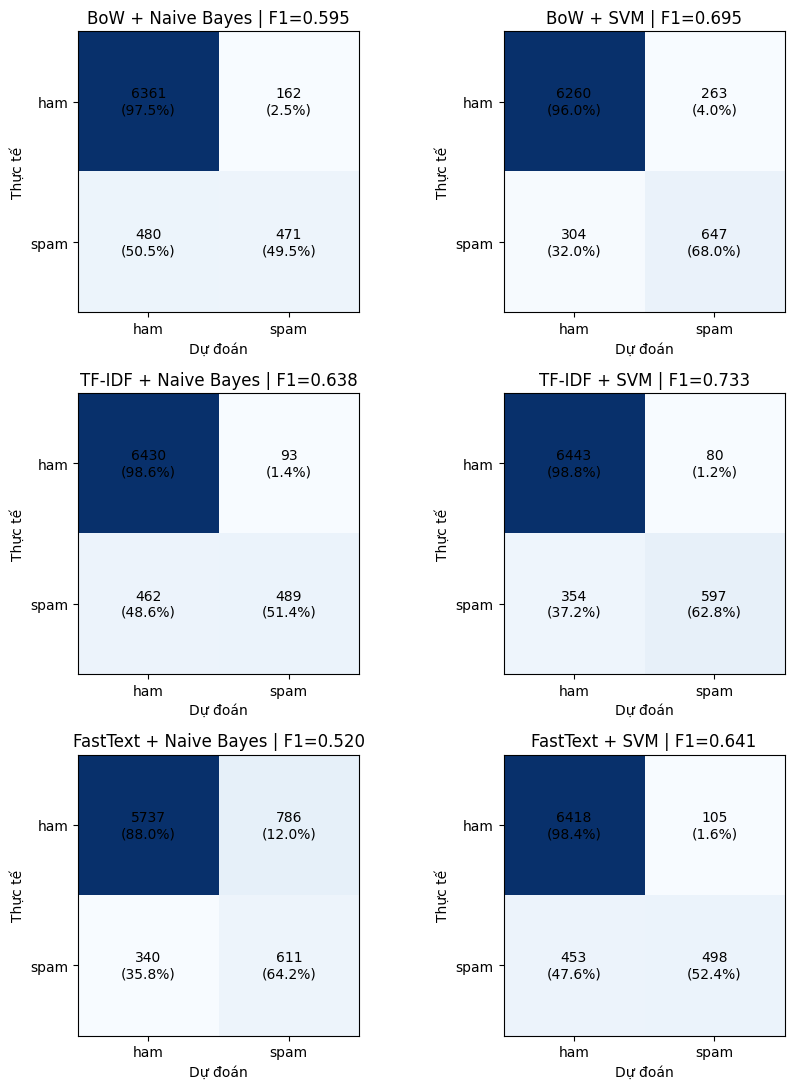

Confusion matrix mô hình cuối (kể cả nếu là thí nghiệm bổ sung):


,đoán ham,đoán spam
thật ham,6443,80
thật spam,354,597


In [13]:
fig, axes = plt.subplots(3, 2, figsize=(9, 11))
for ax, record in zip(axes.ravel(), sel):
    matrix = confusion_matrix(y_test, record["_pred"], labels=[0, 1])
    ax.imshow(matrix, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{matrix[i,j]}\n({matrix[i,j]/matrix[i].sum():.1%})", ha="center", va="center")
    ax.set_xticks([0, 1], ["ham", "spam"]); ax.set_yticks([0, 1], ["ham", "spam"])
    ax.set_xlabel("Dự đoán"); ax.set_ylabel("Thực tế")
    ax.set_title(f"{record['Đặc trưng']} + {record['Thuật toán']} | F1={record['F1']:.3f}")
plt.tight_layout(); plt.show()
print("Confusion matrix mô hình cuối (kể cả nếu là thí nghiệm bổ sung):")
display(pd.DataFrame(confusion_matrix(y_test, best["_pred"], labels=[0, 1]),
                     index=["thật ham", "thật spam"], columns=["đoán ham", "đoán spam"]))


### 5.2. PR curve và bootstrap F1 — phần nâng cao

Bootstrap 500 lần theo dòng để mô tả độ biến động trên test cố định. Các bình luận có
thể phụ thuộc nhóm nên CI không phải bảo đảm tuyệt đối; CI chồng lấp không chứng minh
hai mô hình tương đương. Không dùng CI hoặc test để điều chỉnh mô hình sau đánh giá.

,Đặc trưng,Thuật toán,F1,CI thấp,CI cao
0,BoW,Naive Bayes,0.5947,0.5629,0.6227
1,BoW,SVM,0.6953,0.6724,0.7193
2,TF-IDF,Naive Bayes,0.6380,0.6089,0.6655
3,TF-IDF,SVM,0.7334,0.7106,0.7562
4,FastText,Naive Bayes,0.5204,0.4969,0.5434
5,FastText,SVM,0.6409,0.6148,0.6663


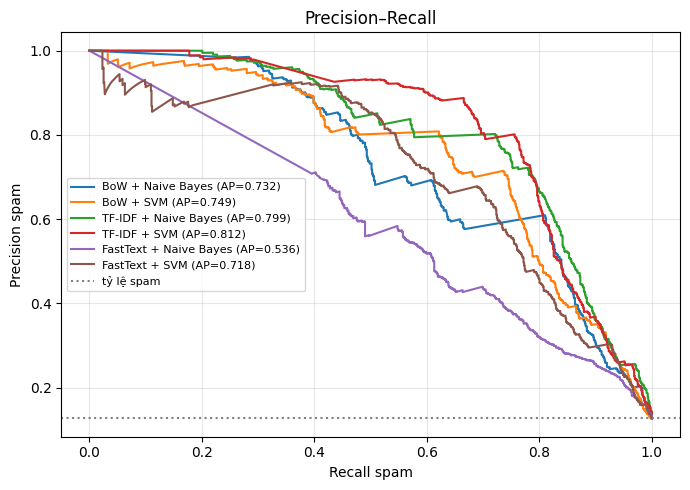

In [14]:
ci = []
for record in sel:
    lo, hi = boot_ci(y_test, record["_pred"])
    ci.append({"Đặc trưng": record["Đặc trưng"], "Thuật toán": record["Thuật toán"], "F1": record["F1"], "CI thấp": lo, "CI cao": hi})
display(pd.DataFrame(ci).round(4))
fig, ax = plt.subplots(figsize=(7, 5))
for record in sel:
    precision, recall, _ = precision_recall_curve(y_test, record["_score"])
    ax.plot(recall, precision, label=f"{record['Đặc trưng']} + {record['Thuật toán']} (AP={record['AP']:.3f})")
ax.axhline(y_test.mean(), ls=":", color="gray", label="tỷ lệ spam")
ax.set(xlabel="Recall spam", ylabel="Precision spam", title="Precision–Recall")
ax.legend(fontsize=8); ax.grid(alpha=.3); plt.tight_layout(); plt.show()


### 5.3. Đối chứng giữ/bỏ stop words — không bắt buộc phải chọn bỏ

Tiền xử lý             có loại stop words  giữ stop words  Δ loại − giữ
Đặc trưng Thuật toán                                                   
BoW       Naive Bayes              0.5930          0.5947       -0.0017
          SVM                      0.6564          0.6953       -0.0389
FastText  Naive Bayes              0.5341          0.5204        0.0136
          SVM                      0.6238          0.6409       -0.0171
TF-IDF    Naive Bayes              0.5987          0.6380       -0.0393
          SVM                      0.7194          0.7334       -0.0140

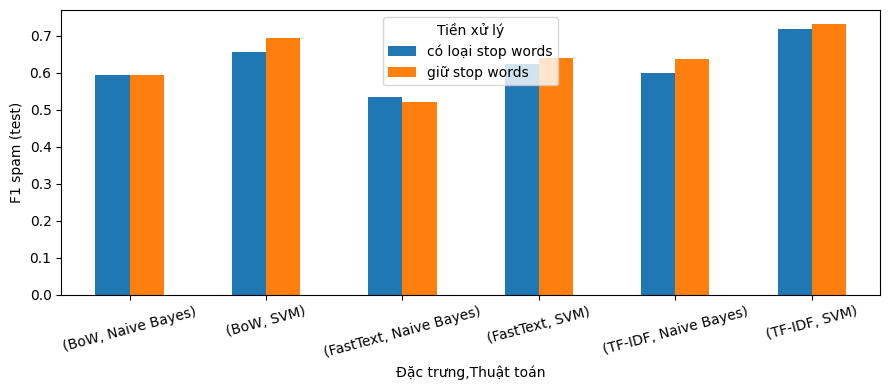

In [15]:
ablation = pd.DataFrame(RESULTS).pivot(index=["Đặc trưng", "Thuật toán"], columns="Tiền xử lý", values="F1")
ablation["Δ loại − giữ"] = ablation["có loại stop words"] - ablation["giữ stop words"]
display(ablation.round(4))
ablation.drop(columns="Δ loại − giữ").plot.bar(figsize=(9, 4), rot=15)
plt.ylabel("F1 spam (test)"); plt.tight_layout(); plt.show()


## 6. Phân tích đặc trưng và lỗi

FP: ham bị báo spam; FN: spam bị bỏ sót. Ví dụ được biểu diễn bằng văn bản đã xử lý.
Các trường hợp cực ngắn hoặc nhãn dựa ngữ cảnh bài đăng/tác giả có thể thiếu dữ kiện
khi mô hình chỉ nhìn một câu. Không tự đổi nhãn chỉ vì mô hình dự đoán khác.

In [16]:
tfidf_svm = next(r for r in sel if r["Đặc trưng"] == "TF-IDF" and r["Thuật toán"] == "SVM")
vec, clf = tfidf_svm["_model"].named_steps["vec"], tfidf_svm["_model"].named_steps["clf"]
names, coefficients = vec.get_feature_names_out(), clf.coef_.ravel()
order = np.argsort(coefficients)
print("Nghiêng về spam:", list(names[order[::-1][:20]]))
print("Nghiêng về ham:", list(names[order[:20]]))
errors = pd.DataFrame({"văn bản xử lý": TEXT[best["Tiền xử lý"]].iloc[test_idx].to_numpy(),
                       "thật": y_test, "đoán": best["_pred"], "score": best["_score"]})
print("FP:"); display(errors[(errors["thật"] == 0) & (errors["đoán"] == 1)].sort_values("score", ascending=False).head(10))
print("FN:"); display(errors[(errors["thật"] == 1) & (errors["đoán"] == 0)].sort_values("score").head(10))


Nghiêng về spam: ['urltoken', 'phonetoken', '.', 'ib chị', 'nhắn_c', 'user_name', 'chiến_lê', '…', 'nguyễn_hữu_trọng', 'aptis', 'mở đơn', ': urltoken', 'up community', 'community', 'emoji_token', 'ib c', 'linh_nhi', 'zalo', 'em vô', 'kỳ nam']
Nghiêng về ham: ['à', 'thôi', ': )', ': (', 'là', 'cảm_ơn', 'quá', 'kìa', 'cũng', 'phải', 'mà', 'vậy', 'thầy', 'đúng', 'ko', 'ạ emoji_token', 'hỏi', 'cô', 'rồi', 'đấy']
FP:


,văn bản xử lý,thật,đoán,score
5260,user_name điên_k emoji_token,0,1,1.010148
1720,user_name poor emoji_token,0,1,1.010148
3666,user_name phonetoken b ib số này nha,0,1,0.968614
4686,chuyên_ngành thương_mại_điện_tử : d26cqtm01-b : urltoken d26cqtm02-b : urltoken d26cqtm03-b : ur...,0,1,0.953824
7233,em nhắn_c gửi nhne,0,1,0.803351
4941,em ib page hoặc nhắn_c nha,0,1,0.713895
5247,user_name đmm,0,1,0.688906
3345,user_name kìaa,0,1,0.688906
4276,user_name ýe,0,1,0.688906
5185,user_name nô,0,1,0.688906


FN:


,văn bản xử lý,thật,đoán,score
4474,"mạn đó thì nhiều lắm b , qtrong b có tìm ra ttam uy_tín được hay k thôi , g ttam mọc lên như gì ...",1,0,-1.348505
5573,chi yen có ạ,1,0,-1.333541
1770,user_name toàn đi cắm r,1,0,-1.328876
3010,em xin vs a ơi,1,0,-1.261907
6712,36 k thì lấy,1,0,-1.256183
5234,đăng dươngg ib bạn này ạ hqua bạn em làm rơi,1,0,-1.250196
3807,nhat anh,1,0,-1.242884
743,martial the tks b nh,1,0,-1.232013
5615,user_name còn k b,1,0,-1.224531
5714,quá uy_tín,1,0,-1.220419


### 6.1. FastText và OOV — phần thêm ngoài yêu cầu tối thiểu

Subword giúp tạo vector từ chưa gặp, không bảo đảm mọi biến thể hiểu đúng.
Từ gần theo cosine có thể gần hình thức hoặc cùng ngữ cảnh, không luôn đồng nghĩa.

In [17]:
ft_svm = next(r for r in sel if r["Đặc trưng"] == "FastText" and r["Thuật toán"] == "SVM")
wv = ft_svm["_model"].named_steps["vec"].wv_
rows = []
for word in ["ib", "zalo", "lịch_thi", "inboxxx", "inb0x", "z.a.l.o"]:
    nearest = wv.most_similar(positive=[wv[word]], topn=5)
    rows.append({"từ": word, "có trong train": word in wv.key_to_index,
                 "vector gần nhất": ", ".join(f"{w} ({v:.2f})" for w, v in nearest)})
display(pd.DataFrame(rows))
only_ft = (y_test == 1) & (tfidf_svm["_pred"] == 0) & (ft_svm["_pred"] == 1)
only_tfidf = (y_test == 1) & (tfidf_svm["_pred"] == 1) & (ft_svm["_pred"] == 0)
print("Spam chỉ FastText bắt được:", int(only_ft.sum()), "| chỉ TF-IDF bắt được:", int(only_tfidf.sum()))


,từ,có trong train,vector gần nhất
0,ib,True,"ib (1.00), ib_e (0.79), ibi (0.78), a_ib (0.75), ib_tớ (0.75)"
1,zalo,True,"zalo (1.00), valo (0.90), sdt (0.89), sđt (0.89), alo (0.88)"
2,lịch_thi,True,"lịch_thi (1.00), lịch_rảnh (0.90), lịch_sử (0.89), lịch_sự (0.89), lịch_k (0.89)"
3,inboxxx,False,"inbox (0.99), inb (0.92), jd (0.89), nerdbox (0.87), box (0.86)"
4,inb0x,False,"inb (0.97), inbox (0.94), valo (0.86), sdt (0.85), addfr (0.84)"
5,z.a.l.o,False,"kcn (0.88), hz (0.88), bùi_nhuận (0.87), series (0.87), instagram (0.86)"


Spam chỉ FastText bắt được: 33 | chỉ TF-IDF bắt được: 132


## 7. Dự đoán bình luận mới và lưu kết quả — phần hỗ trợ

Nhận raw text, dùng cùng preprocessing với train. SVM trả decision score, không phải
xác suất; NB trả xác suất lớp spam, dùng đúng ngưỡng nếu CV chọn chỉnh ngưỡng.
Artifact được tạo khi chạy, không phải file bắt buộc phải đính kèm trước khi chạy notebook.

In [18]:
manifest = {"dataset_repo": HF_REPO_ID, "dataset_revision": HF_REVISION,
    "dataset_sha256": dataset_sha256, "audit": DATA_AUDIT,
    "train_rows": len(train_idx), "test_rows": len(test_idx), "test_spam": int(y_test.sum()),
    "seed": SEED, "environment": ENVIRONMENT, "python": sys.version.split()[0],
    "completed_utc": datetime.now(timezone.utc).isoformat(), "modern_model": "not_implemented",
    "selected": {k: best[k] for k in ["Tiền xử lý", "Đặc trưng", "Thuật toán", "Biến thể", "CV F1 (spam)", *METRICS, "Tham số"]}}
bundle = {"model": best["_model"], "threshold": best.get("_threshold", 0.5),
    "remove_stop": best["Tiền xử lý"] == "có loại stop words", "manifest": manifest,
    "preprocessing_source": inspect.getsource(preprocessing_module),
    "features_source": inspect.getsource(features_module)}
# Cache chỉ phục vụ train; model cuối không phụ thuộc đường dẫn thư mục tạm.
for record in CANDIDATES:
    record["_model"].memory = None
model_path = ARTIFACT_DIR / "spam_ham_ml_only.joblib"
joblib.dump(bundle, model_path)
loaded = joblib.load(model_path)

X_verify = TEXT[best["Tiền xử lý"]].iloc[test_idx].to_numpy()
reloaded_pred, _ = predict_record({"_model": loaded["model"], "_threshold": loaded["threshold"]}, X_verify)
assert np.array_equal(reloaded_pred, best["_pred"])
display(predict_spam(["Cho mình hỏi lịch thi với ạ", "Liên hệ 0901234567 hoặc https://example.com", "Nguyễn Văn An", "."], loaded))
metrics.to_csv(ARTIFACT_DIR / "metrics.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(ci).to_csv(ARTIFACT_DIR / "bootstrap_ci.csv", index=False)
(ARTIFACT_DIR / "run_manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
cache_dir.cleanup()
print("Đã kiểm tra load–predict khớp; metrics và manifest lưu ở", ARTIFACT_DIR)


,text,score,score_type,du_doan
0,Cho mình hỏi lịch thi với ạ,-1.254256,decision_score,ham
1,Liên hệ 0901234567 hoặc https://example.com,2.968799,decision_score,spam
2,Nguyễn Văn An,0.688906,decision_score,spam
3,.,0.986102,decision_score,spam


Đã kiểm tra load–predict khớp; metrics và manifest lưu ở C:\KH086\PT&KP DLVB\PROJECT\ptit-facebook-spam-ham\.work\runs\restructured_training\artifacts


## 8. Nhận xét theo kết quả lần chạy này

Nhận xét bên dưới sinh từ kết quả thực thi, không giữ số liệu của phiên bản notebook cũ.
Không kết luận mô hình hiện đại đã có, không khẳng định một giá trị F1 là trần của bài toán.

In [19]:
observed_top = max(CANDIDATES, key=lambda r: r["F1"])
base = next(r for r in SUPPLEMENTARY if r["Biến thể"] == "class_weight=None")
balanced = next(r for r in SUPPLEMENTARY if r["Biến thể"] == "class_weight=balanced")
summary = f"""
- Dữ liệu: **{len(raw):,}** mẫu; test **{len(test_idx):,}**, spam **{int(y_test.sum()):,}**.
- Chọn bằng CV: **{best['Đặc trưng']} + {best['Thuật toán']} / {best['Biến thể']}**, {best['Tiền xử lý']}.
  Test Precision **{best['Precision']:.2%}**, Recall **{best['Recall']:.2%}**, F1 **{best['F1']:.4f}**, AP **{best['AP']:.4f}**.
- F1 test cao nhất quan sát: {observed_top['Đặc trưng']} + {observed_top['Thuật toán']} / {observed_top['Biến thể']},
  **{observed_top['F1']:.4f}**. Đây là mô tả kết quả test, không thay thế quy tắc chọn theo CV.
- TF-IDF/SVM không class weight: Recall {base['Recall']:.2%}, F1 {base['F1']:.4f};
  balanced: Recall {balanced['Recall']:.2%}, F1 {balanced['F1']:.4f}. Cân bằng lớp có đánh đổi, không luôn tăng mọi chỉ số.
- Có **{DATA_AUDIT['text_groups_with_conflicting_labels']}** nhóm văn bản giống nhau mang nhãn khác nhau;
  chưa tự sửa nhãn khi thiếu ngữ cảnh. Kết quả chỉ đánh giá trên nhãn hiện có và cộng đồng này.
- **Mô hình hiện đại chưa thực hiện**, giới hạn nguồn/lịch sử nhãn được ghi ở docs/provenance; không suy diễn chất lượng nhãn tuyệt đối.
"""
display(Markdown(summary))



- Dữ liệu: **38,233** mẫu; test **7,474**, spam **951**.
- Chọn bằng CV: **TF-IDF + SVM / chính**, giữ stop words.
  Test Precision **88.18%**, Recall **62.78%**, F1 **0.7334**, AP **0.8117**.
- F1 test cao nhất quan sát: TF-IDF + SVM / under-sampling 2:1,
  **0.7542**. Đây là mô tả kết quả test, không thay thế quy tắc chọn theo CV.
- TF-IDF/SVM không class weight: Recall 62.78%, F1 0.7334;
  balanced: Recall 77.92%, F1 0.7451. Cân bằng lớp có đánh đổi, không luôn tăng mọi chỉ số.
- Có **27** nhóm văn bản giống nhau mang nhãn khác nhau;
  chưa tự sửa nhãn khi thiếu ngữ cảnh. Kết quả chỉ đánh giá trên nhãn hiện có và cộng đồng này.
- **Mô hình hiện đại chưa thực hiện**, giới hạn nguồn/lịch sử nhãn được ghi ở docs/provenance; không suy diễn chất lượng nhãn tuyệt đối.


## Tài liệu và đường dẫn code

- Dataset: https://huggingface.co/datasets/p-storm/ptit-facebook-comments-spamham
- Tiền xử lý: `pipeline/prepare/preprocess_for_model.py`.
- Đặc trưng/CV: `pipeline/features/spam_features.py`, `pipeline/modeling/experiments.py`, `training_utils.py`.
- Dự đoán: `pipeline/inference/predict.py`; nguồn và đối soát: `docs/provenance/`.
- Kaggle nhóm đã đối chiếu: https://www.kaggle.com/code/itsmecuong/notebook82c07ebf7a
- underthesea: https://github.com/undertheseanlp/underthesea
- scikit-learn: https://scikit-learn.org/stable/
- Gensim FastText: https://radimrehurek.com/gensim/models/fasttext.html

Ý 2: tiền xử lý; ý 3: ít nhất hai cách đặc trưng; ý 4: NB/SVM và chia tập;
ý 5: chỉ số/Confusion Matrix/so sánh. Ý 4 bổ sung giữ chỗ phía trên. AP/CI/OOV và
demo là phần thêm. Bảng/hình được tạo từ output thật của lần chạy hiện tại.
